# 04 - Baseline models (Dummy and Logistic Regression)

Re-fits the baselines in-notebook on train, scores on validation (never test), and inspects
logistic-regression coefficients. The saved artifacts come from `scripts/train_model.py`.

> Notebooks display **aggregates only** (no individual loan records) and reuse functions from `src/creditiq/`. Educational project - not for real lending decisions.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from creditiq.config import load_config, setup_logging
from creditiq.cli import processed_path, clean_all_path
from creditiq.reporting import figures as figs

setup_logging("WARNING")
cfg = load_config()
figs.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
TARGET = cfg["target"]["name"]

In [2]:
from creditiq.data.split import split_frames
from creditiq.features.build_features import resolve_feature_spec
from creditiq.models.train import train_dummy, train_logistic_regression
from creditiq.models.evaluate import probability_metrics
loans = pd.read_parquet(processed_path(cfg))
frames = split_frames(loans)
spec = resolve_feature_spec(cfg.raw, "applicant")
dummy = train_dummy(frames["train"], TARGET, spec, cfg)
logreg = train_logistic_regression(frames["train"], frames["validation"], TARGET, spec, cfg)
display(logreg.tuning)
yv = frames["validation"][TARGET].to_numpy()
rows = []
for name, fm in (("dummy", dummy), ("logistic_regression", logreg)):
    rows.append({"model": name, **probability_metrics(yv, fm.pipeline.predict_proba(frames["validation"])[:, 1])})
display(pd.DataFrame(rows).set_index("model"))

,C,class_weight,val_roc_auc,val_log_loss,selected
0,0.01,None,0.669832,0.422794,True
1,0.01,balanced,0.669797,0.654863,False
2,0.10,None,0.669773,0.422858,False
3,0.10,balanced,0.669657,0.655078,False
4,1.00,None,0.669758,0.422869,False
5,1.00,balanced,0.669640,0.655078,False


,n,prevalence,mean_predicted,roc_auc,pr_auc,brier,log_loss,ece
model,,,,,,,,
dummy,47013,0.164869,0.157665,0.500000,0.164869,0.137739,0.447850,0.007204
logistic_regression,47013,0.164869,0.161117,0.669832,0.277988,0.130680,0.422794,0.005610


## Coefficients (standardised features; log-odds per 1 SD)

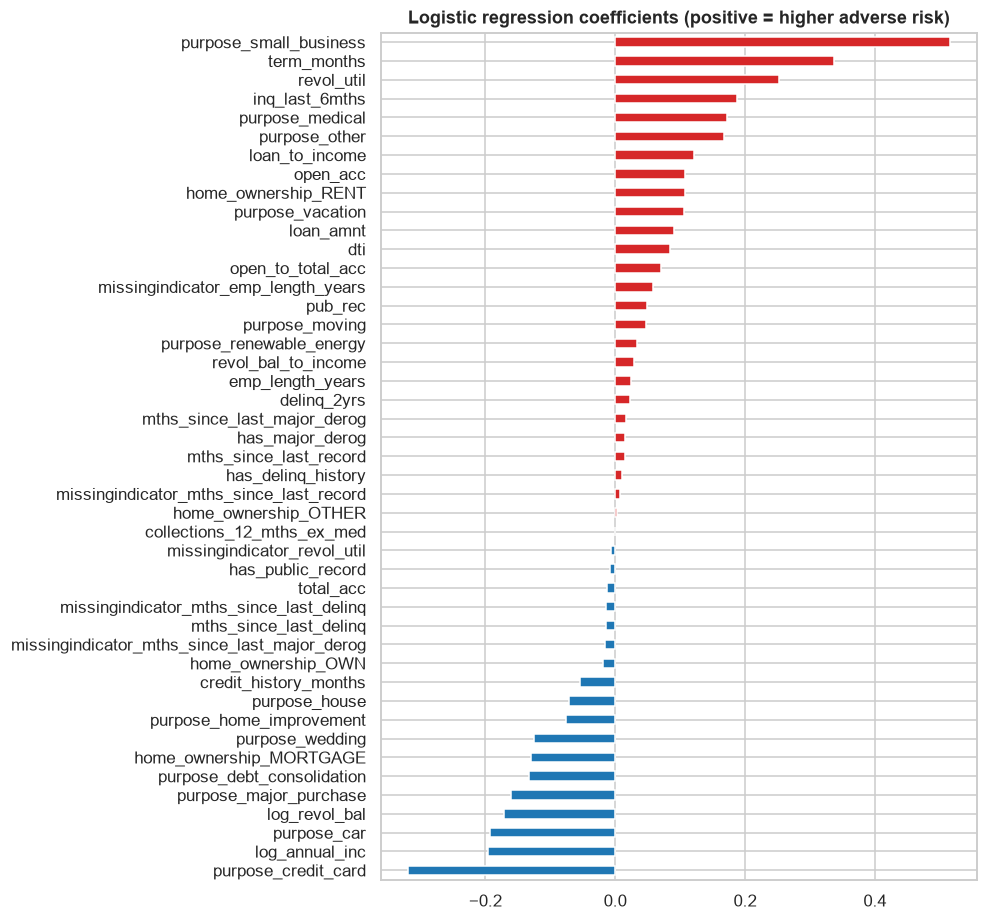

In [3]:
model = logreg.pipeline.named_steps["model"]
names = logreg.pipeline.named_steps["prep"].named_steps["encode"].get_feature_names_out()
coef = pd.Series(model.coef_.ravel(), index=names).sort_values()
ax = coef.plot.barh(figsize=(7, 10), color=np.where(coef > 0, "#d62728", "#1f77b4"))
ax.set_title("Logistic regression coefficients (positive = higher adverse risk)"); plt.show()

Coefficients are conditional associations given the other features; correlated inputs
(e.g. `loan_amnt`, `loan_to_income`, `log_annual_inc`) can share or flip sign. They are not causal.